In [3]:
import ujson

cases = []

with open("consumer_cases_final.jsonl", "r", encoding="utf-8-sig") as f:
    for line in f:
        cases.append(ujson.loads(line))

print("수집한 데이터 개수:", len(cases))
print(cases[0])

수집한 데이터 개수: 100
{'title': '상조상품 가입시 주의사항', 'question': '질문 상조상품 가입시 주의사항은 무엇인가요?', 'answer': '답변 1. 사은품에 현혹되지 마시고, 계약내용을 꼼꼼히 확인하셔야 합니다. 2. 상조상품 계약시 해지 절차와 환급액을 반드시 확인하십시오. 3. 수의 판매 계약인지 상조 서비스 계약인지 확인하십시오. 4. 장례 현장에서 필요하지 않은 물품과 서비스는 거절하고, 표준약관 사용(계약서에 중요한 내용, 특약사항 기재)한 계약서를 받아두십시오.'}


In [9]:
print(len(cases))
print(line)

0
﻿{"title":"상조상품 가입시 주의사항","question":"질문 상조상품 가입시 주의사항은 무엇인가요?","answer":"답변 1. 사은품에 현혹되지 마시고, 계약내용을 꼼꼼히 확인하셔야 합니다. 2. 상조상품 계약시 해지 절차와 환급액을 반드시 확인하십시오. 3. 수의 판매 계약인지 상조 서비스 계약인지 확인하십시오. 4. 장례 현장에서 필요하지 않은 물품과 서비스는 거절하고, 표준약관 사용(계약서에 중요한 내용, 특약사항 기재)한 계약서를 받아두십시오."}



In [ ]:
%pip install ujson


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install konlpy

   ---------------------------------------- 0.0/19.4 MB ? eta -:--:--
   ---- ----------------------------------- 2.1/19.4 MB 10.5 MB/s eta 0:00:02
   --------- ------------------------------ 4.5/19.4 MB 11.0 MB/s eta 0:00:02
   -------------- ------------------------- 7.1/19.4 MB 11.4 MB/s eta 0:00:02
   ------------------- -------------------- 9.4/19.4 MB 11.2 MB/s eta 0:00:01
   ---------------------- ----------------- 11.0/19.4 MB 10.7 MB/s eta 0:00:01
   --------------------------- ------------ 13.4/19.4 MB 10.5 MB/s eta 0:00:01
   ------------------------------- -------- 15.5/19.4 MB 10.4 MB/s eta 0:00:01
   ------------------------------------ --- 17.8/19.4 MB 10.5 MB/s eta 0:00:01
   ---------------------------------------  19.4/19.4 MB 10.3 MB/s eta 0:00:01
   ---------------------------------------- 19.4/19.4 MB 9.8 MB/s  0:00:01
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ----------------------- ---------------- 2.4/4.1 MB 11.8 MB/s eta 0:00:01
  

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from konlpy.tag import Okt

okt = Okt()

text = cases[0]["question"]

result = okt.pos(text, norm=True)
print(result)

JVMNotFoundException: No JVM shared library file (jvm.dll) found. Try setting up the JAVA_HOME environment variable properly.

In [4]:
from konlpy.tag import Okt

okt = Okt()

text = cases[0]["question"]

result = okt.pos(text, norm=True)
print(result)

[('질문', 'Noun'), ('상조', 'Noun'), ('상품', 'Noun'), ('가입', 'Noun'), ('시', 'Noun'), ('주의', 'Noun'), ('사항', 'Noun'), ('은', 'Josa'), ('무엇', 'Noun'), ('인가요', 'Josa'), ('?', 'Punctuation')]


In [5]:
for case in cases:
    case["question_ma"] = okt.pos(case["question"], norm=True)

print(cases[0]["question_ma"])

[('질문', 'Noun'), ('상조', 'Noun'), ('상품', 'Noun'), ('가입', 'Noun'), ('시', 'Noun'), ('주의', 'Noun'), ('사항', 'Noun'), ('은', 'Josa'), ('무엇', 'Noun'), ('인가요', 'Josa'), ('?', 'Punctuation')]


In [6]:
nouns = []

for case in cases:
    for word, tag in case["question_ma"]:
        if tag == "Noun":
            nouns.append(word)

print(nouns[:30])

['질문', '상조', '상품', '가입', '시', '주의', '사항', '무엇', '질문', '상조', '서비스', '가입', '최신', '가전제품', '사은', '품', '월', '납부', '시작', '상조', '서비스', '해지', '가전제품', '할부', '계약', '것', '하나요', '질문', '항공', '편']


In [7]:
stopwords = {"질문", "시", "무엇"}

filtered_nouns = []

for word in nouns:
    if word not in stopwords:
        filtered_nouns.append(word)

print(filtered_nouns[:30])


['상조', '상품', '가입', '주의', '사항', '상조', '서비스', '가입', '최신', '가전제품', '사은', '품', '월', '납부', '시작', '상조', '서비스', '해지', '가전제품', '할부', '계약', '것', '하나요', '항공', '편', '이용', '과정', '골프채', '수하물', '위탁']


In [8]:
from collections import Counter

word_count = Counter(filtered_nouns)

print(word_count.most_common(20))


[('환급', 65), ('수', 53), ('계약', 52), ('사업자', 44), ('결제', 42), ('후', 38), ('요구', 36), ('경우', 29), ('이용', 27), ('이', 27), ('개월', 26), ('구매', 24), ('취소', 24), ('업체', 23), ('체결', 21), ('전', 19), ('중', 19), ('서비스', 18), ('하자', 18), ('것', 17)]


In [9]:
for word, count in word_count.most_common(20):
    print(word, count)

환급 65
수 53
계약 52
사업자 44
결제 42
후 38
요구 36
경우 29
이용 27
이 27
개월 26
구매 24
취소 24
업체 23
체결 21
전 19
중 19
서비스 18
하자 18
것 17


In [10]:
stopwords = {"질문", "시", "무엇", "수", "것",
             "후", "전", "중", "경우", "이", "개월"}

filtered_nouns = []

for word in nouns:
    if word not in stopwords:
        filtered_nouns.append(word)

word_count = Counter(filtered_nouns)

for word, count in word_count.most_common(20):
    print(word, count)

환급 65
계약 52
사업자 44
결제 42
요구 36
이용 27
구매 24
취소 24
업체 23
체결 21
서비스 18
하자 18
통해 17
요 17
구입 17
신용카드 17
해지 16
제품 16
철회 16
위약금 15


In [11]:
stopwords = {"질문", "시", "무엇", "수", "것",
             "후", "전", "중", "경우", "이", "개월",
             "통해", "요"}

filtered_nouns = []

for word in nouns:
    if word not in stopwords:
        filtered_nouns.append(word)

word_count = Counter(filtered_nouns)

for word, count in word_count.most_common(20):
    print(word, count)

환급 65
계약 52
사업자 44
결제 42
요구 36
이용 27
구매 24
취소 24
업체 23
체결 21
서비스 18
하자 18
구입 17
신용카드 17
해지 16
제품 16
철회 16
위약금 15
공제 15
요청 14


In [12]:
%pip install wordcloud

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -----------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


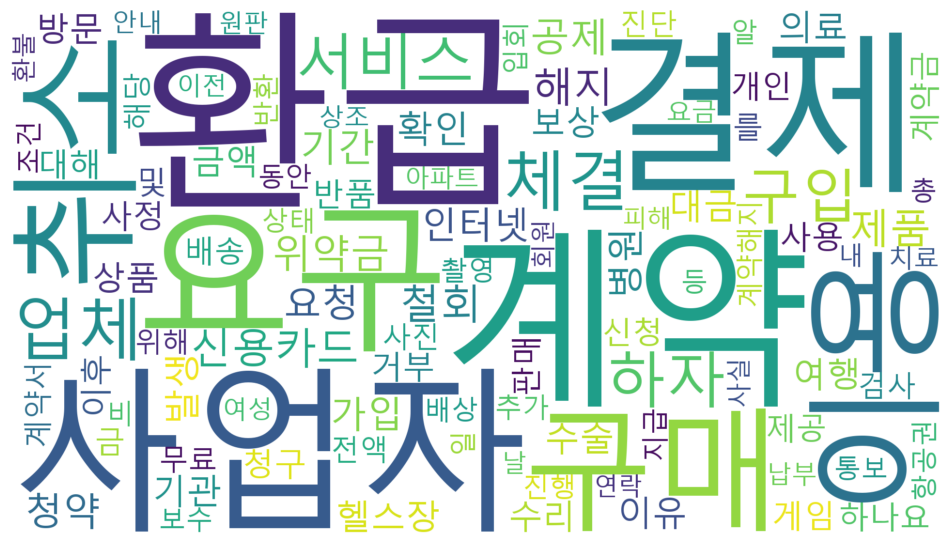

In [14]:
wc = WordCloud(
    background_color="white",
    font_path="C:/Windows/Fonts/malgun.ttf",
    max_words=100,
    collocations=False,
    width=1920,
    height=1080
)

wc.generate_from_frequencies(word_count)

plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.gcf().set_size_inches(12, 10)
plt.show()

In [15]:
wc.to_file("wordcloud.png")

In [16]:
%pip install squarify seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.9 MB 6.6 MB/s eta 0:00:02
   ------ --------------------------------- 1.8/10.9 MB 5.0 MB/s eta 0:00:02
   --------- ------------------------------ 2.6/10.9 MB 4.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.7/10.9 MB 4.5 MB/s eta 0:00:02
   ----------------- ---------------------- 4.7/10.9 MB 4.6 MB/s eta 0:00:02
   ------------------- -------------------- 5.2/10.9 MB 4.3 MB/s eta 0:00:02
   --------------------- ------------------ 5.8/10.9 MB 4.1 MB/s eta 0:00:02
   ----------------------- ---------------- 6.3/10.9 MB 3.9 MB/s eta 0:00:02
   ------------------------- -------------- 6.8/10.9 MB 3.7 MB/s eta 0:00:02
   -------------------------- ------------- 7.1/10.9 MB 3.3 MB/s eta 0:00:02
   -------------------------- ------------- 7.3/10.9 MB 3.2 MB/s eta 0:00:02
   --------------------------- ------------ 7.6/10.9 MB 3.0 MB/s eta 0:00:02
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


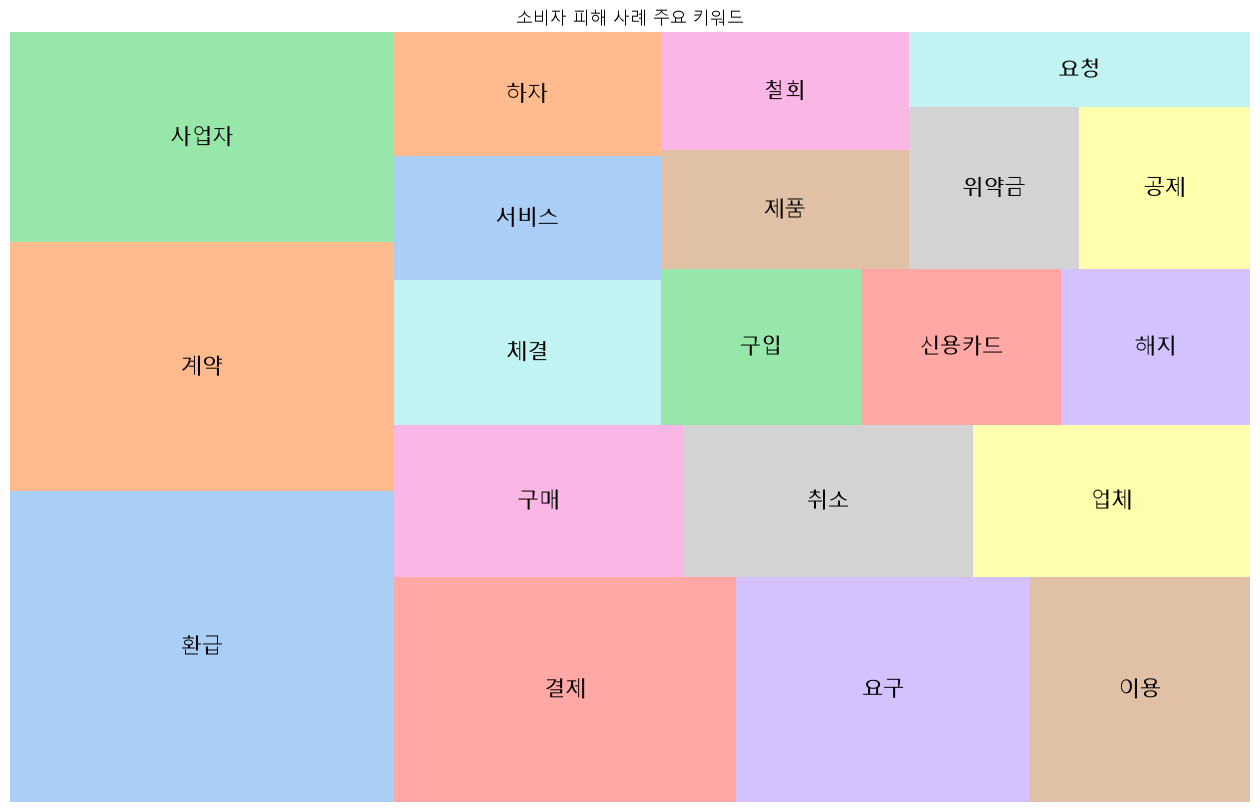

In [17]:
import squarify
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

N_WORDS = 20
COLORS = sns.color_palette("pastel")

matplotlib.rc("font", family="Malgun Gothic")

word_count_pairs = word_count.most_common(N_WORDS)
words, counts = zip(*word_count_pairs)

squarify.plot(
    sizes=counts,
    label=words,
    color=COLORS,
    alpha=0.9,
    text_kwargs={'fontsize': 15}
)

plt.axis("off")
plt.title("소비자 피해 사례 주요 키워드")
plt.gcf().set_size_inches(16, 10)
plt.show()